# **<font color="slategrey">------</font>** **<font color="LIGHTBLUE">METODO</font>** **<font color="slategrey">DE</font>** **<font color="LIGHTBLUE">NEVILLE</font>** **<font color="slategrey">------</font>**

***<font color="LIGHTBLUE">NOMBRE:</font>*** CUEVAS COYAZO ISABELLA

***<font color="slategrey">GRUPO:</font>*** 3MV1

**<font color="slategrey">>>></font>** **<font color="LIGHTBLUE">DEFINICION</font>** **<font color="slategrey"><<<</font>**

**<font color="LIGHTBLUE"> - </font>** Sea **<font color="slategrey"> ${f}$ </font>** una funcion definida en **<font color="slategrey"> ${X_0, X_1,..., X_n}$ </font>** y supongamos que **<font color="slategrey"> ${m_1, m_2,..., m_k}$ </font>** son **<font color="slategrey"> ${k}$ </font>** enteros distintos con **<font color="slategrey"> ${0<=m_i<=n}$ </font>** para cada **<font color="slategrey"> ${i}$ </font>**.
El polinomio dde lagrange que concuerda con **<font color="slategrey"> ${f}$ </font>** en los **<font color="slategrey"> ${K}$ </font>** puntos **<font color="slategrey"> ${X_m1, X_m2,..., X_mk}$ </font>** se denota por: **<font color="slategrey"> $${P_m1,_m2,...,_mk (X)}$$ </font>**

**<font color="LIGHTBLUE"> - </font>** El metodo de neville nos ayudara a calcular aproximaciones del polinomio de interpolacion utilizando una formula recursiva, mediante un conjunto de nodos y sus valores conocidos, donde asi tendremos polinomios de grados que va de menor a mayor hasta llegar a la proximacion que queremos. **<font color="slategrey"> $$Q_{i,j}=
\frac{
(x-x_{i-j})Q_{i,j-1}-
(x-x_i)Q_{i-1,j-1}
}{
x_i-x_{i-j}
}$$</font>**

**<font color="slategrey">>>></font>** **<font color="LIGHTBLUE">EJERCICIO</font>** **<font color="slategrey"><<<</font>**

**<font color="LIGHTBLUE"> - </font>** Los valores de diferentes polinomios de interpolación en **<font color="slategrey">${X=1.5}$</font>** se obtuvieron en la ilustración al inicio de esta sección usando **<font color="slategrey">los datos que se muestran en la tabla 3.5</font>**. Aplique el método de Neville a los datos mediante la construcción de  **<font color="slategrey">una tabla recursiva de la forma que se observa en la tabla 3.4.</font>**

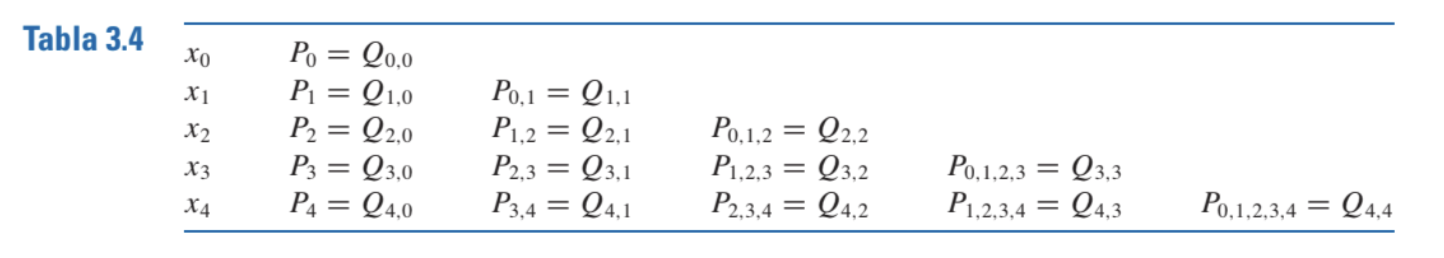

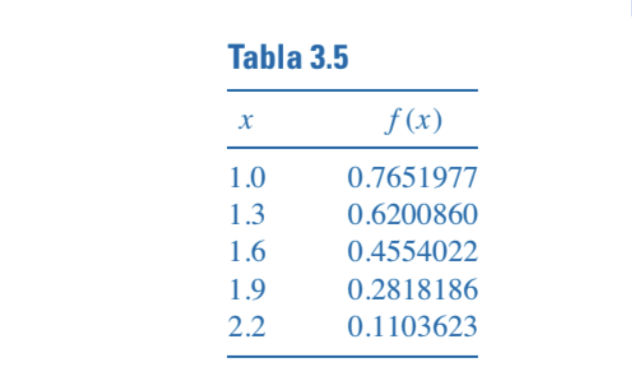


 **<font color="slategrey">-----------------------------------</font>** **<font color="LIGHTBLUE">CODIGO</font>** **<font color="slategrey">----------------------------------</font>**

**<font color="LIGHTBLUE">1- </font>** **Importamos la libreria numpy que nos ayuda ya que contiene funciones matematicas.**

In [41]:
import numpy as np

**<font color="LIGHTBLUE">2- </font>** **Ahora definimos el punto, y convertimos en lista a los los nodos asi como a los valores dados en el ejercicio.**

In [42]:
#punto donde queremos evaluar el polinomio
x=1.5    

nodos=[1.0, 1.3, 1.6, 1.9, 2.2]   

valores=[0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]

In [32]:
#cuenta el numero de nodos que hay en la lista
n=len(nodos)

print("PUNTO DE APROXIMACION: ",x)
print("NUMERO DE NODOS: ",n)

PUNTO DE APROXIMACION:  1.5
NUMERO DE NODOS:  5


**<font color="LIGHTBLUE">3- </font>** **Definimos la funcion que contiene el procedimiento del metodo de neville**

In [33]:
def mneville(x, nodos, valores):

#cuenta la cantidad de nodos en la lista para saber el tamaño de la matriz (tabla)
    n=len(nodos)

#hacemos una matriz Q de 5*5 de solo ceros para agregar los calculos del metodo de neville
    Q=[[0.0 for j in range(n)] for i in range(n)] 

#agregamos la lista de los valores en la primera columna de la matriz 
    for i in range(n):
        Q[i][0]=valores[i]

#calculamos las aproximaciones
    for i in range(1,n): #filas 
        for j in range(1,i+1): #columnas

#formula de neville
           Q[i][j] = ((x - nodos[i-j]) * Q[i][j-1] - (x - nodos[i]) * Q[i-1][j-1]) / (nodos[i] - nodos[i-j])

#regresamos la matriz con los reultados
    return Q

**<font color="LIGHTBLUE">4- </font>** **Tabla**

In [44]:
#los resultados de la funcion los guardamosen Q
Q=mneville(x,nodos,valores)

print("                                 METODO DE NEVILLE")
print()

#encabezado
print(f"{'x':>10}{'F(x)':>14}{'P1':>14}{'P2':>14}{'P3':>14}{'P4':>14}")
print ()

#resultados de filas
for i in range(n):
    print(f"{nodos[i]:>10.4f}", end="") #mostramos los nodos de cada fila

#resultados de columnas
    for j in range(n):
        if j<=i:
            print(f"{Q[i][j]:>14.7f}", end="")
        else:
            print(f"{'':>14}", end="")
    print ()        


                                 METODO DE NEVILLE

         x          F(x)            P1            P2            P3            P4

    1.0000     0.7651977                                                        
    1.3000     0.6200860     0.5233449                                          
    1.6000     0.4554022     0.5102968     0.5124715                            
    1.9000     0.2818186     0.5132634     0.5112857     0.5118127              
    2.2000     0.1103623     0.5104270     0.5137361     0.5118302     0.5118200


**<font color="LIGHTBLUE">5- </font>** **Ahora identificamos la aproximacion final de neville.**

In [45]:
resultado=Q[n-1][n-1]

print("RESULTADO FINAL")
print()
print(f"P({x})={resultado:.7f}")

RESULTADO FINAL

P(1.5)=0.5118200


 **<font color="slategrey">--------------------------------------------</font>** **<font color="LIGHTBLUE">GRAFICA</font>** **<font color="slategrey">------------------------------------------</font>**

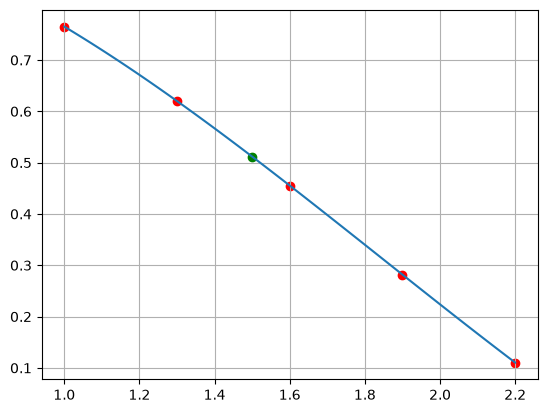

In [56]:
#generamos los puntos para la grafica
xx = np.linspace(min(nodos), max(nodos), 100)

#calculamos los valores del polinomio
yy = [mneville(p, nodos, valores)[n-1][n-1] for p in xx]

#graficamos polinomio, nodos y la aproximapacion obtenida para x=1.5
plt.plot(xx, yy)
plt.scatter(nodos, valores, color="red")
plt.scatter(x, resultado, color="green")

#para la cuadricula
plt.grid()
plt.show()

 **<font color="slategrey">--------------------------------------------</font>** **<font color="LIGHTBLUE">CONCLUSION</font>** **<font color="slategrey">------------------------------------------</font>**

**Mediante el metodo de neville tenemos que la aproximacion final de la funcion en el punto x=1.5 es de 0.5118200, que esta en la ultima posicion de la digonal de la tabla en P4**